# Printing-Demand Pressure → U.S. Paper Manufacturing

**Executed, reproducible fixed-snapshot macro pilot (2026-10-27).** This notebook independently inspects data, constructs the signal, audits purged OOS origins, recomputes metrics, displays real plots and interprets 1,000/2,000-draw diagnostics. **Not historical point-in-time; not issuer fundamentals; not equity alpha.**

Underlying industrial data: [Federal Reserve G.17 October 16, 2026](https://www.federalreserve.gov/releases/g17/20261016/default.htm), [FRED paper](https://fred.stlouisfed.org/series/IPG322S), [FRED printing](https://fred.stlouisfed.org/series/IPG323S).

## 01. Abstract

**Primary question:** Does a two-month-stale printing-versus-manufacturing production gap improve three-month-ahead U.S. paper manufacturing output growth forecasts? We distinguish positive retrospective prediction from point-in-time implementability and tradable stock alpha. All numeric claims below are recomputed from frozen CSVs; no company-return data exist.

In [1]:
import json, numpy as np, pandas as pd, matplotlib.pyplot as plt
from pathlib import Path
from IPython.display import display
from analysis import ROOT, load_data, build_panel, walk_forward, score, rmse_improvement, rank_spread, HORIZON, LAG, MIN_TRAIN, ALPHA
plt.rcParams.update({'figure.figsize':(8,4.2),'font.size':10})
summary=json.loads((ROOT/'results/summary.json').read_text())
display(pd.DataFrame([summary]).T.rename(columns={0:'computed_value'}))

,computed_value
n_raw,201
n_panel,184
n_oos,120
first_origin,2016-07-01
last_origin,2026-06-01
improvement_log_pp,0.272414
block_bootstrap_ci_95,"[0.03289937003225969, 0.5703127698333431]"
block_permutation_exploratory_tail,0.014985
perturbation_positive_share,1.0
quintile_macro_growth_spread_log_pp,-2.044807


## 02. Research Design & Hypotheses

**H1 (incremental information):** the fixed printing gap improves OOS RMSE over paper-persistence plus manufacturing controls. **H2 (benchmark relevance):** augmented RMSE also beats the historical mean and paper persistence. **H3 (transportability):** the gain survives block-aware placebo, bootstrap, source-weight changes, year deletions, alternative horizons and structural regimes. **Null:** no incremental forecasting gain. A single positive RMSE is not sufficient for H3.

In [2]:
raw=load_data();panel=build_panel(raw);pred=walk_forward(panel);metrics=score(pred)
assert len(raw)==201 and len(pred)==summary['n_oos']
print('Observations:',len(raw),'Formation rows:',len(panel),'OOS origins:',len(pred))
print('Predefined horizon / input stale months / Ridge alpha:',HORIZON,LAG,ALPHA)

Observations: 201 Formation rows: 184 OOS origins: 120
Predefined horizon / input stale months / Ridge alpha: 3 2 10.0


In [3]:
display(metrics.round(4))
print('H1 improvement (control minus augmented RMSE):',round(rmse_improvement(pred),5))
print('H2 versus mean and persistence:',float(metrics.set_index('model').loc['augmented','rmse_log_pp'])<min(metrics.set_index('model').loc[['mean','persistence'],'rmse_log_pp']))

,model,n,rmse_log_pp,mae_log_pp,temporal_pearson_ic
0,mean,120,4.5586,3.3226,0.0617
1,persistence,120,4.2909,3.1639,0.2582
2,macro_controls,120,4.4476,3.3908,0.1961
3,factor_only,120,4.5386,3.3739,0.1733
4,augmented,120,4.1752,3.0821,0.3173


H1 improvement (control minus augmented RMSE): 0.27241
H2 versus mean and persistence: True


## 03. Industry Context

NAICS **322** paper manufacturing includes paper mills, paperboard and converted products; NAICS **323** printing is one downstream customer group, not a measured revenue-weighted cross-industry demand basket. The relevant 2026 industry market size and paper sales attributable to printing are **UNKNOWN**. Source: [2022 Census NAICS manual](https://www.census.gov/naics/reference_files_tools/2022_NAICS_Manual.pdf).

In [4]:
display(raw.head(3));display(raw.tail(3))

,date,manufacturing_ip,paper_ip,printing_ip
0,2010-01-01,91.0661,99.9533,102.8123
1,2010-02-01,91.0289,101.1013,102.6418
2,2010-03-01,92.1506,101.9735,102.7745


,date,manufacturing_ip,paper_ip,printing_ip
198,2026-07-01,98.3983,79.3207,73.0153
199,2026-08-01,98.1741,79.2102,72.6832
200,2026-09-01,98.4387,78.3155,74.0432


In [5]:
desc=raw[['paper_ip','printing_ip','manufacturing_ip']].agg(['min','max','mean','std']).T
display(desc.round(3))

,min,max,mean,std
paper_ip,78.316,105.119,95.690,8.282
printing_ip,69.230,106.879,92.597,10.422
manufacturing_ip,79.771,101.877,97.954,2.836


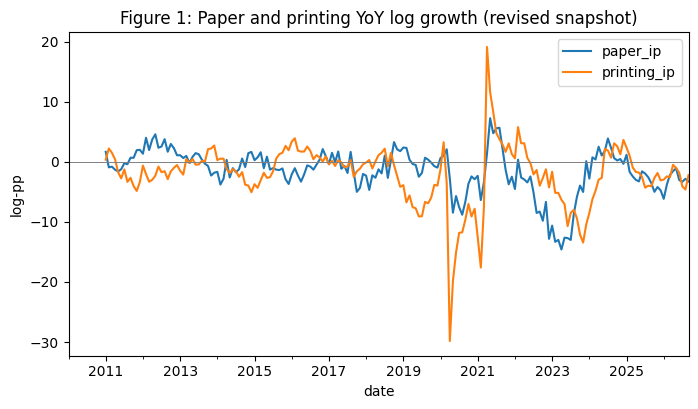

In [6]:
growth=raw.set_index('date')[['paper_ip','printing_ip','manufacturing_ip']].apply(lambda s:100*np.log(s/s.shift(12)))
growth[['paper_ip','printing_ip']].plot(title='Figure 1: Paper and printing YoY log growth (revised snapshot)')
plt.axhline(0,color='gray',lw=.7);plt.ylabel('log-pp');plt.show()

## 04. Data & Source Integrity

The 2010-01 to 2026-09 frozen panel is inherited from a previous manually transcribed G.17 industry study, not downloaded as independent historical releases. The official underlying publisher is A-grade, but inherited transcription is a material additional data-quality risk. Ten recent values have been independently spot-checked against the public FRED pages; **the other 593 have not been independently audited**. Annual benchmark and monthly revisions may change historical rows.

In [7]:
sources=pd.read_csv(ROOT/'data/source_register.csv');display(sources[['source_id','grade','series','source_release_date','historical_vintages_verified','limitation']])

,source_id,grade,series,source_release_date,historical_vintages_verified,limitation
0,A1,A,G322 Paper manufacturing IP,2026-10-16,NO,Underlying official series but inherited trans...
1,A2,A,G323 Printing and related support IP,2026-10-16,NO,Printing not all paper end-use; vintage and tr...
2,A3,A,B00004 Manufacturing IP,2026-10-16,NO,Aggregate manufacturing includes paper and pri...
3,B1,B,FRED IPG322S and IPG323S metadata,UNKNOWN,NO,NaN
4,B2,B,ALFRED historical-vintage discovery,UNKNOWN,NO,NaN
5,C1,C,2022 NAICS structure manual,2022,NO,No company-level exposure weights


In [8]:
print('Raw missing by column:',raw.isna().sum().to_dict())
print('Duplicate dates:',raw.date.duplicated().sum(),'Monthly continuity:',raw.date.diff().dropna().dt.days.between(28,31).all())
assert raw[['paper_ip','printing_ip','manufacturing_ip']].gt(0).all().all()

Raw missing by column: {'date': 0, 'manufacturing_ip': 0, 'paper_ip': 0, 'printing_ip': 0}
Duplicate dates: 0 Monthly continuity: True


In [9]:
checks=pd.read_csv(ROOT/'data/official_spot_checks_2026-10-27.csv',parse_dates=['date']);indexed=raw.set_index('date')
checks['frozen_value']=[indexed.loc[r.date,r.series] for r in checks.itertuples()]
checks['exact_match']=np.isclose(checks.official_value,checks.frozen_value,atol=1e-8,rtol=0)
display(checks[['date','series','official_value','frozen_value','exact_match']]);assert checks.exact_match.all()

,date,series,official_value,frozen_value,exact_match
0,2026-05-01,paper_ip,79.9955,79.9955,True
1,2026-06-01,paper_ip,79.6852,79.6852,True
2,2026-07-01,paper_ip,79.3207,79.3207,True
3,2026-08-01,paper_ip,79.2102,79.2102,True
4,2026-09-01,paper_ip,78.3155,78.3155,True
5,2026-05-01,printing_ip,76.1858,76.1858,True
6,2026-06-01,printing_ip,75.7245,75.7245,True
7,2026-07-01,printing_ip,73.0153,73.0153,True
8,2026-08-01,printing_ip,72.6832,72.6832,True
9,2026-09-01,printing_ip,74.0432,74.0432,True


## 05. Point-in-Time Availability

**No PIT proof.** Inputs use month **t−2**, outcome is **t+3**, and training labels are admitted only when their outcome observation month is at most **t−2**. This enforces a conservative mechanical delay and a 5-month gap between the last training formation and each test origin; it **does not** reconstruct original release vintages or solve future revisions.

In [10]:
display(panel[['date','feature_month','target_month','paper_lag','printing_lag','manufacturing_lag','factor','target']].head(5).round(3))

,date,feature_month,target_month,paper_lag,printing_lag,manufacturing_lag,factor,target
0,2011-03-01,2011-01-01,2011-06-01,1.664,0.349,4.613,-4.264,-1.224
1,2011-04-01,2011-02-01,2011-07-01,-0.926,2.219,4.831,-2.613,-0.233
2,2011-05-01,2011-03-01,2011-08-01,-0.807,1.505,4.228,-2.723,-0.393
3,2011-06-01,2011-04-01,2011-09-01,-1.309,0.420,2.904,-2.484,0.685
4,2011-07-01,2011-05-01,2011-10-01,-1.596,-1.746,1.636,-3.383,0.668


In [11]:
display(pred[['origin','target_month','train_last_target_month','train_n']].head(8))
assert (pred.train_last_target_month<=pred.origin-pd.DateOffset(months=LAG)).all()
print('All origins pass assumed outcome-publication purge; PIT vintage status: UNKNOWN / NOT VERIFIED')

,origin,target_month,train_last_target_month,train_n
0,2016-07-01,2016-10-01,2016-05-01,60
1,2016-08-01,2016-11-01,2016-06-01,61
2,2016-09-01,2016-12-01,2016-07-01,62
3,2016-10-01,2017-01-01,2016-08-01,63
4,2016-11-01,2017-02-01,2016-09-01,64
5,2016-12-01,2017-03-01,2016-10-01,65
6,2017-01-01,2017-04-01,2016-11-01,66
7,2017-02-01,2017-05-01,2016-12-01,67


All origins pass assumed outcome-publication purge; PIT vintage status: UNKNOWN / NOT VERIFIED


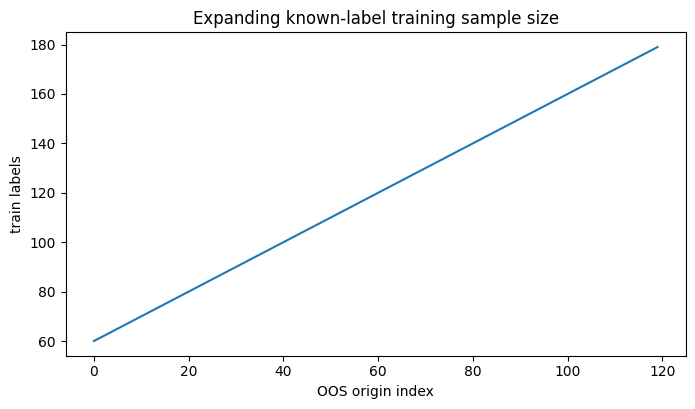

In [12]:
pred.train_n.plot(title='Expanding known-label training sample size')
plt.xlabel('OOS origin index');plt.ylabel('train labels');plt.show()

## 06. Factor Construction

Let $g^X_t=100[\log(IP^X_t)-\log(IP^X_{t-12})]$. The predeclared factor is $F_t=g^{printing}_{t-2}-g^{manufacturing}_{t-2}$ and the target is $Y_t=g^{paper}_{t+3}$. Each Ridge model uses training-only standardization and fixed $\alpha=10$; no future-mean scaling or optimized exposure weights. Overlapping 12-month growth windows imply serially dependent targets.

In [13]:
row=panel.iloc[0];indexed=raw.set_index('date')
fp=100*np.log(indexed.loc[row.feature_month,'printing_ip']/indexed.loc[row.feature_month-pd.DateOffset(months=12),'printing_ip'])
fm=100*np.log(indexed.loc[row.feature_month,'manufacturing_ip']/indexed.loc[row.feature_month-pd.DateOffset(months=12),'manufacturing_ip'])
assert np.isclose(row.factor,fp-fm)
print('Independent first-factor equation check:',round(row.factor,6),round(fp-fm,6))

Independent first-factor equation check: -4.264151 -4.264151


In [14]:
display(panel[['paper_lag','printing_lag','manufacturing_lag','factor','target']].corr().round(3))

,paper_lag,printing_lag,manufacturing_lag,factor,target
paper_lag,1.000,0.402,0.378,0.202,0.482
printing_lag,0.402,1.000,0.731,0.716,-0.031
manufacturing_lag,0.378,0.731,1.000,0.047,0.200
factor,0.202,0.716,0.047,1.000,-0.250
target,0.482,-0.031,0.200,-0.250,1.000


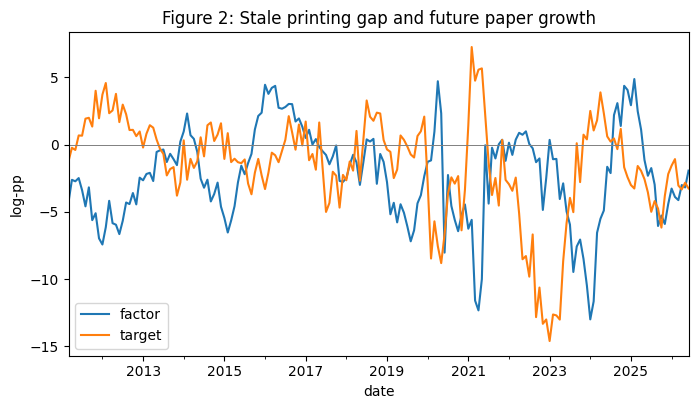

In [15]:
panel.set_index('date')[['factor','target']].plot(title='Figure 2: Stale printing gap and future paper growth')
plt.axhline(0,color='gray',lw=.7);plt.ylabel('log-pp');plt.show()

## 07. Exposure & Transmission

The industry mapping is dated and sourced but **not** an issuer revenue-share mapping. Unit indicators `1.0` are structural roles, not measured customer weights. Printing may lead orders for some paper grades, but packaging and tissue demand can break the relationship. Firm-level segment weights and issuer histories are unavailable, so leave-one-company-out is explicitly **NOT APPLICABLE**.

In [16]:
exposure=pd.read_csv(ROOT/'data/exposure_map.csv');display(exposure)

,entity,naics,role,proxy_weight,as_of,source_url,evidence,company_exposure_status,notes
0,U.S. Paper Manufacturing,322,target,1.0,2026-10-16,https://fred.stlouisfed.org/series/IPG322S,Official industry output proxy,NOT_ESTABLISHED,Includes packaging tissue and other paper prod...
1,U.S. Printing and Related Support,323,signal,1.0,2026-10-16,https://fred.stlouisfed.org/series/IPG323S,Official downstream activity proxy,NOT_ESTABLISHED,Not a documented share of paper producer revenue
2,U.S. Manufacturing,31-33,control,1.0,2026-10-16,https://www.federalreserve.gov/releases/g17/,Official aggregate cyclical control,NOT_ESTABLISHED,Contains target and signal components
3,Issuer universe,UNKNOWN,not_tested,NaN,2026-10-27,UNKNOWN,No dated segment revenue/issuer universe/total...,UNKNOWN,Leave-one-company-out and equity-alpha metrics...


In [17]:
pert=pd.read_csv(ROOT/'results/exposure_perturbation_1000.csv')
print('1,000 ±20% proxy perturbations: positive share',round((pert.control_minus_augmented_rmse>0).mean(),4))
display(pert.control_minus_augmented_rmse.describe().to_frame('RMSE_gain').round(4))

1,000 ±20% proxy perturbations: positive share 1.0


,RMSE_gain
count,1000.0000
mean,0.2712
std,0.0039
min,0.2563
25%,0.2697
50%,0.2725
75%,0.2741
max,0.2749


## 08. Outcomes & Baselines

The target is an **industry output** growth rate, not sales, earnings, or total return. All 120 origins use the same purged training set. Five forecasts are compared: training mean; paper persistence; paper plus manufacturing controls; printing gap only; augmented controls plus printing gap. Pearson IC is a **temporal macro prediction correlation**, not cross-sectional security Rank IC.

In [18]:
display(metrics.set_index('model').round(4))

,n,rmse_log_pp,mae_log_pp,temporal_pearson_ic
model,,,,
mean,120,4.5586,3.3226,0.0617
persistence,120,4.2909,3.1639,0.2582
macro_controls,120,4.4476,3.3908,0.1961
factor_only,120,4.5386,3.3739,0.1733
augmented,120,4.1752,3.0821,0.3173


In [19]:
display(pred[['origin','actual','mean','persistence','macro_controls','factor_only','augmented','train_n']].head(6).round(3))

,origin,actual,mean,persistence,macro_controls,factor_only,augmented,train_n
0,2016-07-01,0.367,0.068,-0.956,-1.858,-2.331,-2.547,60
1,2016-08-01,2.122,0.058,-0.278,-1.089,-2.210,-2.054,61
2,2016-09-01,0.913,0.044,-0.370,-1.492,-2.033,-2.133,62
3,2016-10-01,-0.370,0.023,-0.607,-1.655,-1.496,-1.868,63
4,2016-11-01,1.497,0.015,-0.214,-1.153,-1.514,-1.602,64
5,2016-12-01,-0.057,0.020,0.168,-0.767,-1.196,-1.190,65


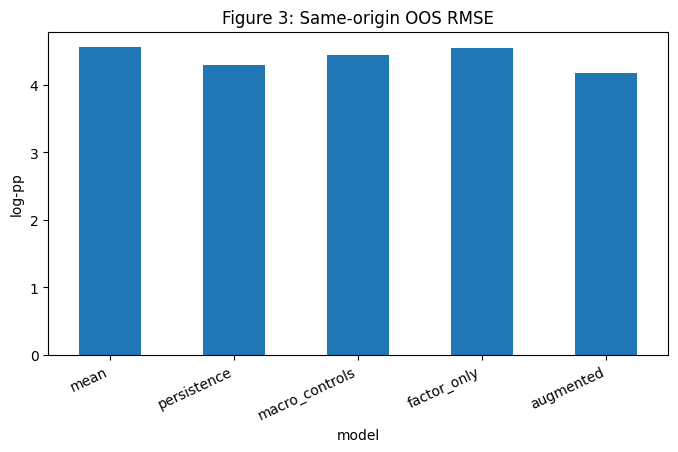

In [20]:
fig,ax=plt.subplots();metrics.set_index('model').rmse_log_pp.plot.bar(ax=ax,title='Figure 3: Same-origin OOS RMSE')
ax.set_ylabel('log-pp');plt.xticks(rotation=25,ha='right');plt.show()

## 09. Empirical Findings

The augmented RMSE is **4.175** versus **4.448** for controls, **4.291** for persistence and **4.559** for mean. The factor-only model is **4.539**, so incremental performance depends on conditioning. The sign of the raw factor-quintile spread is negative, contradicting a simple monotone downstream-demand story. No profit, return or benchmark-adjusted spread is computed.

In [21]:
gain=rmse_improvement(pred);print('Incremental RMSE gain:',gain,'relative to controls:',gain/metrics.set_index('model').loc['macro_controls','rmse_log_pp'])

Incremental RMSE gain: 0.2724137045368522 relative to controls: 0.06124927345831553


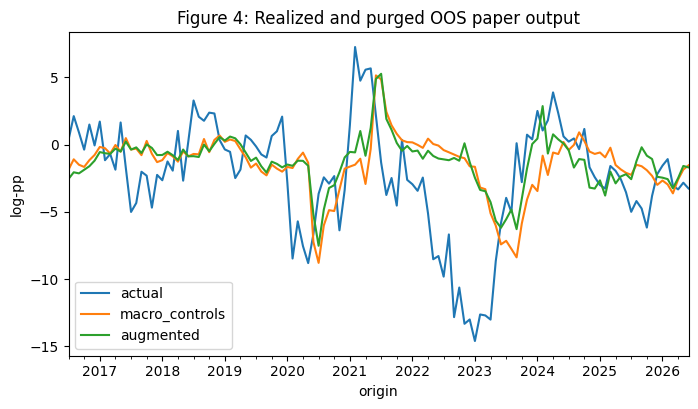

In [22]:
fig,ax=plt.subplots();pred.set_index('origin')[['actual','macro_controls','augmented']].plot(ax=ax,title='Figure 4: Realized and purged OOS paper output')
ax.set_ylabel('log-pp');plt.show()

Mean paired squared-loss difference (positive favors factor): 2.3489779308941774


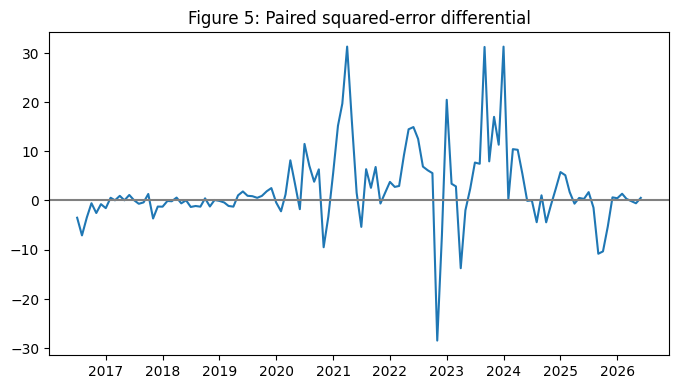

In [23]:
loss=(pred.actual-pred.macro_controls)**2-(pred.actual-pred.augmented)**2
print('Mean paired squared-loss difference (positive favors factor):',loss.mean())
fig,ax=plt.subplots();ax.plot(pred.origin,loss);ax.axhline(0,color='gray');ax.set_title('Figure 5: Paired squared-error differential');plt.show()

In [24]:
ranks,macro_spread=rank_spread(pred);display(ranks)
print('Top-minus-bottom factor-quintile subsequent paper growth:',macro_spread,'log-pp; NOT a security return spread')

,mean,count
factor_quintile,,
0,-0.027756,24
1,-2.846367,24
2,-3.748052,24
3,-3.235692,24
4,-2.072563,24


Top-minus-bottom factor-quintile subsequent paper growth: -2.044806984377623 log-pp; NOT a security return spread


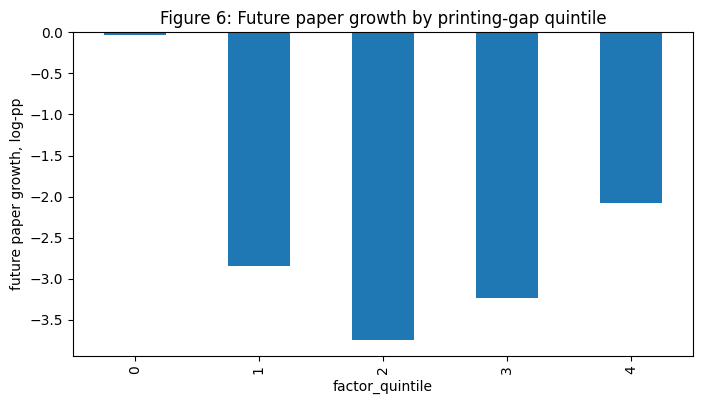

In [25]:
fig,ax=plt.subplots();ranks['mean'].plot.bar(ax=ax,title='Figure 6: Future paper growth by printing-gap quintile')
ax.set_ylabel('future paper growth, log-pp');plt.show()

## 10. Robustness & Placebos

All bootstrap and shuffle arrays below were **actually generated by `python run_analysis.py`**, and their numeric values are stored. The notebook recomputes intervals and the plus-one exploratory tail from those arrays. The 12-month contiguous-block permutation preserves within-block order but is **not an exact p-value** under overlapping targets, nonstationarity and retrospective revisions. The 2,000-draw circular bootstrap samples paired OOS error vectors.

In [26]:
boot=pd.read_csv(ROOT/'results/block_bootstrap_2000.csv').improvement_log_pp.to_numpy()
assert len(boot)==2000
ci=np.quantile(boot,[.025,.975]);print('Paired 2000-draw circular block bootstrap 95% CI:',ci)

Paired 2000-draw circular block bootstrap 95% CI: [0.03289937 0.57031277]


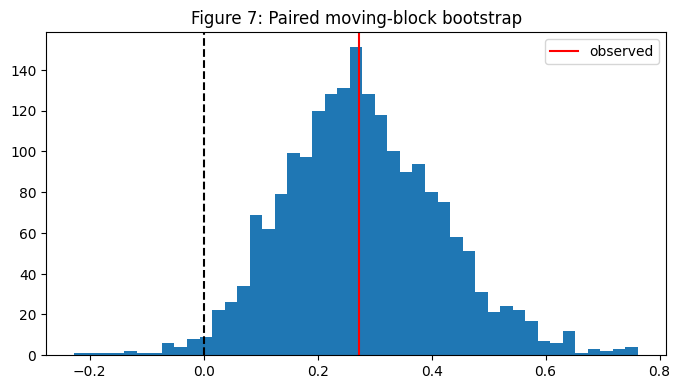

In [27]:
fig,ax=plt.subplots();ax.hist(boot,bins=45);ax.axvline(0,color='black',ls='--');ax.axvline(gain,color='red',label='observed');ax.legend();ax.set_title('Figure 7: Paired moving-block bootstrap');plt.show()

In [28]:
perm=pd.read_csv(ROOT/'results/block_permutation_1000.csv').placebo_improvement_log_pp.to_numpy()
assert len(perm)==1000
tail=(np.sum(perm>=gain)+1)/(len(perm)+1)
print('1000 block-shuffle exploratory upper-tail fraction (NOT exact p-value):',tail)

1000 block-shuffle exploratory upper-tail fraction (NOT exact p-value): 0.014985014985014986


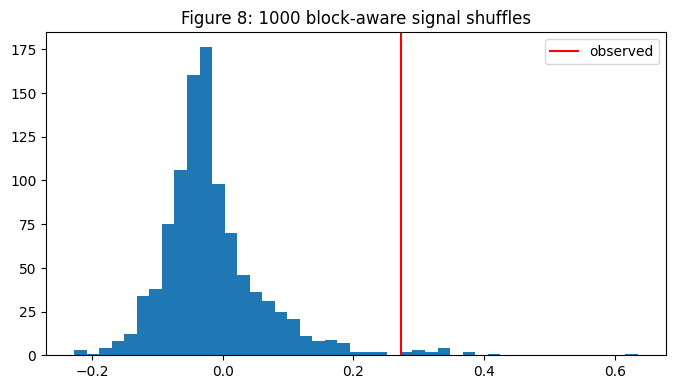

In [29]:
fig,ax=plt.subplots();ax.hist(perm,bins=45);ax.axvline(gain,color='red',label='observed');ax.legend();ax.set_title('Figure 8: 1000 block-aware signal shuffles');plt.show()

In [30]:
loo=pd.read_csv(ROOT/'results/leave_one_year_out.csv');display(loo.round(4))
print('LOYO positive share:',(loo.gain_log_pp>0).mean(),'This is leave-one-YEAR-out, not leave-one-company-out.')

,excluded_year,n,gain_log_pp
0,2016,114,0.3001
1,2017,108,0.2966
2,2018,108,0.2973
3,2019,108,0.2828
4,2020,108,0.2770
5,2021,108,0.1993
6,2022,108,0.3061
7,2023,108,0.2155
8,2024,108,0.2389
9,2025,108,0.3053


LOYO positive share: 1.0 This is leave-one-YEAR-out, not leave-one-company-out.


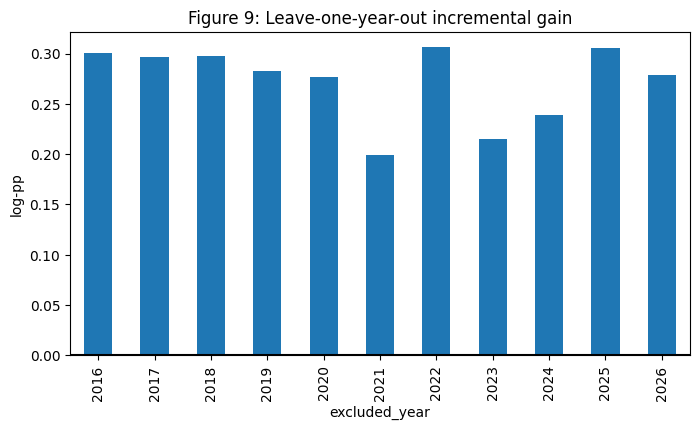

In [31]:
fig,ax=plt.subplots();loo.plot.bar(x='excluded_year',y='gain_log_pp',ax=ax,legend=False,title='Figure 9: Leave-one-year-out incremental gain')
ax.axhline(0,color='black');ax.set_ylabel('log-pp');plt.show()

## 11. Regime Sensitivity

Pre-2020 incremental RMSE improvement is negative, while post-2021 is positive. Excluding the pandemic still leaves a smaller positive gain, but a 12-month prediction horizon reverses sign. These are exploratory robustness views, not independent confirmatory trials; overlapping OOS labels reduce effective independent information.

In [32]:
reg=pd.read_csv(ROOT/'results/regimes.csv');display(reg.round(4))

,regime,n,gain_log_pp,mean_rmse
0,pre_2020,42,-0.1070,2.0530
1,2020_2021,24,0.5488,4.8468
2,post_2021,54,0.3167,5.6974
3,exclude_2020_2021,96,0.1953,4.4837


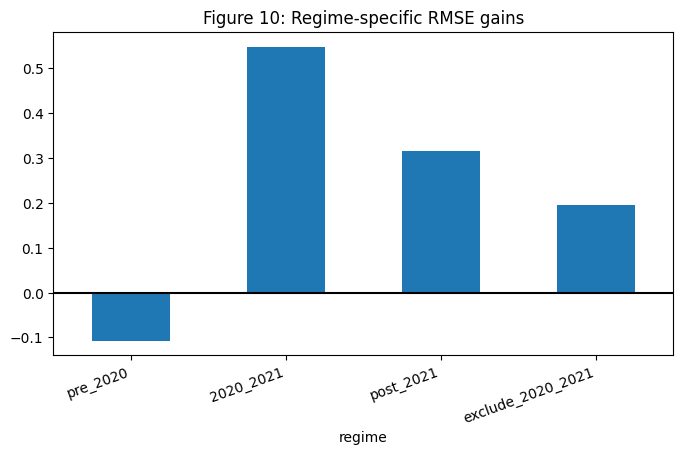

In [33]:
fig,ax=plt.subplots();reg.plot.bar(x='regime',y='gain_log_pp',ax=ax,legend=False,title='Figure 10: Regime-specific RMSE gains')
ax.axhline(0,color='black');plt.xticks(rotation=20,ha='right');plt.show()

In [34]:
hl=pd.read_csv(ROOT/'results/horizon_lag_sensitivity.csv')
display(hl.pivot(index='horizon',columns='lag',values='control_minus_augmented_rmse').round(3))
print('Predeclared primary h=3, lag=2; all other cells exploratory')

lag,1,2,3
horizon,,,
1,0.040,0.104,0.215
3,0.215,0.272,0.374
6,0.392,0.328,0.225
12,-0.200,-0.392,-0.491


Predeclared primary h=3, lag=2; all other cells exploratory


## 12. Bias Audit & Verdict

**PIT/revisions:** no historical release-specific input panel. **Transcription:** 10/603 independent spot checks only. **Selection/multiple tests:** many industries and 12 exploratory horizon-lag variants; no familywise adjustment. **Temporal overlap:** 12-month growth autocorrelation. **Exposure:** no dated issuer sales mix. **Costs/survivorship:** no tradable securities or historical universe. **Verdict:** conditional retrospective macro lead-factor candidate, **not validated PIT**, **not investable equity alpha**; H3 fails pre-2020 and 12-month horizon.

In [35]:
audit=pd.DataFrame([['Historical PIT','FAIL: no release-specific vintages'],['Issuer revenue','NOT TESTED'],['Total-return alpha','NOT TESTED'],['OOS controls','PASS: same 120 origins'],['Block-aware placebo','EXPLORATORY ONLY'],['Pre-2020 transportability','FAIL: negative gain'],['2026 source transcription','PARTIAL: 10 of 603 values spot-checked']],columns=['risk','status'])
display(audit)

,risk,status
0,Historical PIT,FAIL: no release-specific vintages
1,Issuer revenue,NOT TESTED
2,Total-return alpha,NOT TESTED
3,OOS controls,PASS: same 120 origins
4,Block-aware placebo,EXPLORATORY ONLY
5,Pre-2020 transportability,FAIL: negative gain
6,2026 source transcription,PARTIAL: 10 of 603 values spot-checked


In [36]:
print('Computed verdict:', 'POSITIVE RETROSPECTIVE OOS MACRO CANDIDATE' if gain>0 else 'NEGATIVE MACRO PILOT')
print('Historical PIT: UNVERIFIED; company fundamentals: NOT TESTED; equity total returns: NOT TESTED')

Computed verdict: POSITIVE RETROSPECTIVE OOS MACRO CANDIDATE
Historical PIT: UNVERIFIED; company fundamentals: NOT TESTED; equity total returns: NOT TESTED


## 13. Reproduction

From a fresh checkout: `pip install -r requirements.txt`; `python run_analysis.py` to reproduce all 1,000/2,000/1,000-draw files; `python -m pytest -q tests`; `python -m jupyter nbconvert --to notebook --execute --inplace research.ipynb`. The script uses fixed random seeds, fixed primary model and train-only preprocessing. GitHub's layout validator is a separate structural check and does not certify data vintages.

In [37]:
files=['results/oos_predictions.csv','results/scorecard.csv','results/block_bootstrap_2000.csv','results/block_permutation_1000.csv','results/exposure_perturbation_1000.csv']
display(pd.DataFrame([{'artifact':p,'bytes':(ROOT/p).stat().st_size} for p in files]))

,artifact,bytes
0,results/oos_predictions.csv,21016
1,results/scorecard.csv,404
2,results/block_bootstrap_2000.csv,39123
3,results/block_permutation_1000.csv,20981
4,results/exposure_perturbation_1000.csv,60978


In [38]:
import hashlib
for name in ['results/scorecard.csv','results/block_permutation_1000.csv','results/block_bootstrap_2000.csv']:
 print(name,hashlib.sha256((ROOT/name).read_bytes()).hexdigest())

results/scorecard.csv d34088aca7c4779929edf3814591036ce4d8b28b4559fffb6975ccae3fe999dd
results/block_permutation_1000.csv 4478400e0fcb637b74a1d5464d3669dbe43ed9793f4ede805ae6e64d14119249
results/block_bootstrap_2000.csv e25c7dbec17da0ee84fa2de487d5872be5699d4d857cb5fd82bdd5dac5e05845


## 14. Next-Stage Protocol

Rebuild historical ALFRED vintages and exact publication timestamps first, then independently verify every row. Replace the weak single downstream proxy with corrugated box orders, packaging and tissue segments; quantify revenue-weighted paper demand using dated issuer filings. Only after fundamental validation should a delisting-aware total-return panel be evaluated against sector benchmarks, turnover and trading costs. Pre-register a new holdout and multiple-testing plan before any investable-alpha claim.

In [39]:
next_steps=pd.DataFrame([['Release-vintage reconstruction','PIT availability','NOT DONE'],['Independent raw series audit','603 source cells','10 spot-checked'],['Issuer segment revenue mapping','dated filing data','NOT DONE'],['Adjusted total returns and costs','security universe','NOT DONE'],['Prospective out-of-sample holdout','new observations','NOT DONE']],columns=['next_stage','needed_data','status']);display(next_steps)

,next_stage,needed_data,status
0,Release-vintage reconstruction,PIT availability,NOT DONE
1,Independent raw series audit,603 source cells,10 spot-checked
2,Issuer segment revenue mapping,dated filing data,NOT DONE
3,Adjusted total returns and costs,security universe,NOT DONE
4,Prospective out-of-sample holdout,new observations,NOT DONE


## 15. Sources & Artifacts

Primary: [Federal Reserve G.17 2026-10-16](https://www.federalreserve.gov/releases/g17/20261016/default.htm), [G.17 series download](https://www.federalreserve.gov/releases/g17/Current/ipdisk/ip_sa.txt). Secondary: [FRED IPG322S](https://fred.stlouisfed.org/series/IPG322S), [FRED IPG323S](https://fred.stlouisfed.org/series/IPG323S), [ALFRED vintages](https://alfred.stlouisfed.org/release?rid=13). Industry classification: [Census 2022 NAICS](https://www.census.gov/naics/reference_files_tools/2022_NAICS_Manual.pdf). The source register contains precise URLs, observed periods, release date, revision policy and provenance; no historical PIT claim.

In [40]:
artifacts=pd.DataFrame([{'category':p.name,'files':len(list(p.glob('*')))} for p in [ROOT/'data',ROOT/'results',ROOT/'figures',ROOT/'tests',ROOT/'logs']]);display(artifacts)

,category,files
0,data,5
1,results,10
2,figures,10
3,tests,2
4,logs,2


In [41]:
assert len(boot)==2000 and len(perm)==1000 and len(pert)==1000
assert np.isclose(gain,summary['improvement_log_pp']) and np.allclose(ci,summary['block_bootstrap_ci_95'])
assert np.isclose(tail,summary['block_permutation_exploratory_tail'])
print('ALL NOTEBOOK CONSISTENCY ASSERTIONS PASSED; evidence level: RETROSPECTIVE MACRO PILOT, NOT PIT OR EQUITY ALPHA')

ALL NOTEBOOK CONSISTENCY ASSERTIONS PASSED; evidence level: RETROSPECTIVE MACRO PILOT, NOT PIT OR EQUITY ALPHA
